# HEALPix-tile codec bench: which *existing* compressor wins?

Pivot (see chat): the custom `healpix-compress` DWT/SPIHT codec is dropped
from consideration -- the conclusion after extensive tuning is that it does
not compete with established codecs. This notebook instead asks a narrower
question: given the HEALPix quadtree architecture (gather every fine-level
cell under one coarser-level cell into a 2-D tile, then compress that tile),
**which already-existing, well-known compressor performs best**?

Loads the HEALPix tile data already written to disk by the earlier
`compress_test.ipynb` run (`data/all_image_cell.npy`,
`data/all_image_data.npy`) instead of re-deriving it from raw Sentinel-2
sources -- keeps this notebook short and fast to re-run while debugging.

Codecs compared, all applied directly to the HEALPix-NESTED tile (no UTM
grid, no reprojection, no NDVI -- RMSE is computed tile-to-tile on the same
grid):

- **zfp**, **SZ3** -- already benchmarked in the main notebook.
- **JPEG 2000** (lossy + lossless) -- already benchmarked; wavelet-based,
  the clearest "known tool that exploits scale correlation" already in use.
- **JPEG XL** (lossy + lossless) -- new here; its Squeeze transform
  (lossless/near-lossless path) and VarDCT (lossy path) are both
  multiscale, so it is another well-established, actively-maintained
  format that exploits cross-scale correlation.
- **DWT + zstd** -- a deliberately simple, textbook baseline (PyWavelets
  wavelet transform + uniform quantisation + zstd), included specifically
  because it is a *generic, well-known* technique that uses scale
  correlation -- distinct from the custom SPIHT/zero-tree engineering in
  `hcc`, which is no longer part of this comparison.
- **uncompressed** -- reference point only (ratio = 1 line).

Produces exactly two figures (colour-blind-safe Okabe-Ito palette + marker
shapes, per request): `fig_error_at_constant_size` and
`fig_storage_at_constant_rmse`.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
FIGURES_DIR = Path("figures")
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

# --- make `hcc` importable (only used for the Z-order <-> 2-D tile utility,
# not for the healpix-compress codec itself) ---------------------------------
import sys
try:
    import hcc  # noqa: F401
except ModuleNotFoundError:
    repo = Path.cwd().parent
    if (repo / "hcc" / "__init__.py").exists():
        sys.path.insert(0, str(repo))
from hcc.compression.zorder import expand_tile

# --- colour-blind-safe palette (Okabe & Ito, 2008) + distinct markers -------
# Each codec gets both a distinct colour AND a distinct marker shape, so the
# figures stay legible even under the most common colour-vision deficiencies
# (and in grayscale printouts).
CODEC_STYLE = {
    "zfp":               dict(color="#0072B2", marker="o"),  # blue
    "sz3":                dict(color="#D55E00", marker="s"),  # vermillion
    "jpeg2000_lossy":     dict(color="#009E73", marker="^"),  # bluish green
    "jpeg2000_lossless":  dict(color="#000000", marker="*"),  # black
    "jpegxl_lossy":       dict(color="#CC79A7", marker="D"),  # reddish purple
    "jpegxl_lossless":    dict(color="#E69F00", marker="P"),  # orange
    "dwt_zstd":           dict(color="#56B4E9", marker="v"),  # sky blue
}
plt.rcParams["figure.figsize"] = (8, 5.5)
plt.rcParams["font.size"] = 11

In [2]:
# --- load already-written HEALPix tile data ---------------------------------
# `c[k]`/`v[k]`: NESTED cell ids / resampled values for the dominant
# level-20 HEALPix "carrier tile" of scene k (all fine cells under one
# coarser-level cell -- exactly the quadtree gather the new architecture is
# about), as written by compress_test.ipynb's data-derivation cells.
SCENE_NAMES = ["urban", "water", "forest", "agriculture", "snow_ice", "clouds", "ocean"]

cell_path = DATA_DIR / "all_image_cell.npy"
data_path = DATA_DIR / "all_image_data.npy"
if not (cell_path.exists() and data_path.exists()):
    raise FileNotFoundError(
        f"Expected {cell_path} and {data_path} -- run compress_test.ipynb's "
        "cell 10 (data derivation) once first; this notebook only reuses "
        "that cached output, it does not re-derive it from raw Sentinel-2 data."
    )
v = np.load(data_path)  # shape (n_scenes, 1024*1024)
assert v.shape[0] == len(SCENE_NAMES), (
    f"v.shape[0]={v.shape[0]} != len(SCENE_NAMES)={len(SCENE_NAMES)} -- "
    "SCENE_NAMES must match the row order used when data/all_image_*.npy was written."
)

TILES = {name: expand_tile(v[k]).astype(np.float32) for k, name in enumerate(SCENE_NAMES)}
tile_shape = next(iter(TILES.values())).shape
raw_bytes = int(np.prod(tile_shape) * 4)  # float32
print(f"{len(TILES)} scenes, tile shape {tile_shape}, raw size {raw_bytes/1e6:.2f} MB each")
for name, t in TILES.items():
    print(f"  {name:<12} min={np.nanmin(t):.3f} max={np.nanmax(t):.3f} mean={np.nanmean(t):.3f}")

7 scenes, tile shape (1024, 1024), raw size 4.19 MB each
  urban        min=-0.025 max=1.678 mean=0.091
  water        min=-0.004 max=0.484 mean=0.002
  forest       min=0.000 max=0.558 mean=0.031
  agriculture  min=0.000 max=0.387 mean=0.103
  snow_ice     min=0.000 max=1.005 mean=0.938
  clouds       min=0.000 max=1.392 mean=0.640
  ocean        min=0.000 max=0.013 mean=0.009


In [3]:
# --- codec adapters ----------------------------------------------------------
from dataclasses import dataclass


@dataclass
class CodecRunResult:
    codec: str
    config: dict
    total_bytes: int
    encode_seconds: float
    decode_seconds: float
    reconstruction: np.ndarray


def _rmse(a, b):
    mask = np.isfinite(a) & np.isfinite(b)
    return float(np.sqrt(np.mean((a[mask] - b[mask]) ** 2))) if mask.any() else np.nan


def encode_zfp(tile, *, tolerance):
    import zfpy
    tile = np.asarray(tile, dtype=np.float32)
    t0 = time.perf_counter()
    enc = zfpy.compress_numpy(tile, tolerance=float(tolerance))
    t1 = time.perf_counter()
    dec = zfpy.decompress_numpy(enc)
    t2 = time.perf_counter()
    return CodecRunResult("zfp", dict(tolerance=float(tolerance)), len(enc), t1 - t0, t2 - t1, dec)


def encode_sz3(tile, *, abs_error):
    from pysz import sz as _sz, szConfig, szErrorBoundMode
    tile = np.ascontiguousarray(np.asarray(tile, dtype=np.float32))
    config = szConfig()
    config.errorBoundMode = szErrorBoundMode.ABS
    config.absErrorBound = float(abs_error)
    t0 = time.perf_counter()
    compressed, _ = _sz.compress(tile, config)
    t1 = time.perf_counter()
    dec, _ = _sz.decompress(compressed, np.float32, tile.shape)
    t2 = time.perf_counter()
    total_bytes = int(getattr(compressed, "nbytes", None) or len(compressed))
    return CodecRunResult("sz3", dict(abs_error=float(abs_error)), total_bytes, t1 - t0, t2 - t1,
                           np.asarray(dec, dtype=np.float32))


def _to_u16(tile):
    tile = np.asarray(tile, dtype=np.float32)
    t_min, t_max = float(tile.min()), float(tile.max())
    span = (t_max - t_min) or 1.0
    return ((tile - t_min) / span * 65535).astype(np.uint16), t_min, span


def _from_u16(u16, t_min, span):
    return u16.astype(np.float32) / 65535.0 * span + t_min


def encode_jpeg2000_lossy(tile, *, quality):
    import io
    from PIL import Image
    u16, t_min, span = _to_u16(tile)
    factor = max(1, int(quality))  # never let it round to 0 (past bug, see main notebook)
    buf = io.BytesIO()
    t0 = time.perf_counter()
    Image.fromarray(u16).save(buf, format="jpeg2000", quality_mode="rates", quality_layers=[factor])
    t1 = time.perf_counter()
    total_bytes = buf.tell()
    buf.seek(0)
    dec_u16 = np.array(Image.open(buf), dtype=np.uint16)
    t2 = time.perf_counter()
    return CodecRunResult("jpeg2000_lossy", dict(quality=factor), total_bytes, t1 - t0, t2 - t1,
                           _from_u16(dec_u16, t_min, span))


def encode_jpeg2000_lossless(tile, **_ignored):
    import imagecodecs
    u16, t_min, span = _to_u16(tile)
    t0 = time.perf_counter()
    enc = imagecodecs.jpeg2k_encode(u16, level=0)
    t1 = time.perf_counter()
    dec_u16 = imagecodecs.jpeg2k_decode(enc)
    t2 = time.perf_counter()
    return CodecRunResult("jpeg2000_lossless", {}, len(enc), t1 - t0, t2 - t1,
                           _from_u16(dec_u16, t_min, span))


_jpegxl_warned = False


def encode_jpegxl_lossy(tile, *, level):
    # imagecodecs' `level` for jpegxl follows its shared 0-100 convention
    # across codecs (100 ~ visually lossless / near-lossless, not literally
    # lossless -- see encode_jpegxl_lossless for that). If the installed
    # imagecodecs version uses a different kwarg name, this fails loudly
    # once with a clear message instead of silently corrupting the sweep.
    global _jpegxl_warned
    import imagecodecs
    u16, t_min, span = _to_u16(tile)
    t0 = time.perf_counter()
    try:
        enc = imagecodecs.jpegxl_encode(u16, level=int(level))
    except TypeError as e:
        if not _jpegxl_warned:
            print(f"[jpegxl] encode signature mismatch ({e}) -- check your imagecodecs "
                  "version's jpegxl_encode kwargs and adjust this adapter. Skipping jpegxl.")
            _jpegxl_warned = True
        raise
    t1 = time.perf_counter()
    dec_u16 = imagecodecs.jpegxl_decode(enc)
    t2 = time.perf_counter()
    return CodecRunResult("jpegxl_lossy", dict(level=int(level)), len(enc), t1 - t0, t2 - t1,
                           _from_u16(dec_u16, t_min, span))


def encode_jpegxl_lossless(tile, **_ignored):
    import imagecodecs
    u16, t_min, span = _to_u16(tile)
    t0 = time.perf_counter()
    enc = imagecodecs.jpegxl_encode(u16, lossless=True)
    t1 = time.perf_counter()
    dec_u16 = imagecodecs.jpegxl_decode(enc)
    t2 = time.perf_counter()
    return CodecRunResult("jpegxl_lossless", {}, len(enc), t1 - t0, t2 - t1,
                           _from_u16(dec_u16, t_min, span))


def encode_dwt_zstd(tile, *, wavelet="db4", levels=4, quantize_bits):
    # Deliberately simple, well-known technique (PyWavelets + uniform
    # quantisation + zstd) -- a generic scale-correlation-exploiting
    # baseline, NOT the custom hcc SPIHT/zero-tree machinery this notebook
    # is moving away from.
    import pywt
    import zstandard as zstd
    tile = np.asarray(tile, dtype=np.float32)
    t0 = time.perf_counter()
    coeffs = pywt.wavedec2(tile, wavelet=wavelet, level=levels, mode="periodization")
    arr, slices = pywt.coeffs_to_array(coeffs)
    max_level = (1 << (quantize_bits - 1)) - 1
    scale = float(np.max(np.abs(arr))) or 1.0
    dtype_q = np.int8 if quantize_bits <= 8 else np.int16
    q = np.round(np.clip(arr / scale * max_level, -max_level, max_level)).astype(dtype_q)
    payload = zstd.ZstdCompressor(level=19).compress(q.tobytes())
    t1 = time.perf_counter()
    total_bytes = len(payload) + 4  # + float32 scale sidecar
    q2 = np.frombuffer(zstd.ZstdDecompressor().decompress(payload), dtype=dtype_q).reshape(arr.shape)
    arr2 = (q2.astype(np.float32) / max_level * scale).astype(np.float64)
    coeffs2 = pywt.array_to_coeffs(arr2, slices, output_format="wavedec2")
    dec = pywt.waverec2(coeffs2, wavelet=wavelet, mode="periodization").astype(np.float32)
    t2 = time.perf_counter()
    return CodecRunResult("dwt_zstd", dict(wavelet=wavelet, levels=levels, quantize_bits=quantize_bits),
                           total_bytes, t1 - t0, t2 - t1, dec)


def encode_uncompressed(tile, **_ignored):
    tile = np.asarray(tile, dtype=np.float32)
    return CodecRunResult("uncompressed", {}, tile.nbytes, 0.0, 0.0, tile.copy())

In [4]:
# --- sweeps (kept modest -- this notebook is meant to iterate fast) --------
ZFP_SWEEP = [dict(tolerance=float(v)) for v in np.logspace(-5, -1, 8)]
SZ3_SWEEP = [dict(abs_error=float(v)) for v in np.logspace(-5, -1, 8)]
JPEG2000_LOSSY_SWEEP = [dict(quality=q) for q in (2, 5, 10, 20, 40, 80)]
JPEGXL_LOSSY_SWEEP = [dict(level=lv) for lv in (20, 40, 60, 75, 85, 95)]
DWT_ZSTD_SWEEP = [dict(quantize_bits=b) for b in (4, 6, 8, 10, 12, 14, 16)]

CODEC_RUNS = {
    "zfp": (encode_zfp, ZFP_SWEEP),
    "sz3": (encode_sz3, SZ3_SWEEP),
    "jpeg2000_lossy": (encode_jpeg2000_lossy, JPEG2000_LOSSY_SWEEP),
    "jpeg2000_lossless": (encode_jpeg2000_lossless, [dict()]),
    "jpegxl_lossy": (encode_jpegxl_lossy, JPEGXL_LOSSY_SWEEP),
    "jpegxl_lossless": (encode_jpegxl_lossless, [dict()]),
    "dwt_zstd": (encode_dwt_zstd, DWT_ZSTD_SWEEP),
    "uncompressed": (encode_uncompressed, [dict()]),
}

rows = []
for scene, tile in TILES.items():
    for codec, (fn, sweep) in CODEC_RUNS.items():
        for cfg in sweep:
            try:
                run = fn(tile, **cfg)
            except Exception as e:
                print(f"[skip] {codec} {cfg} on {scene}: {type(e).__name__}: {e}")
                continue
            rmse = _rmse(tile, run.reconstruction)
            rows.append(dict(
                scene=scene, codec=run.codec, config_json=json.dumps(run.config),
                total_bytes=run.total_bytes, rmse=rmse,
                encode_seconds=run.encode_seconds, decode_seconds=run.decode_seconds,
            ))
    print(f"done: {scene}")

rd_df = pd.DataFrame(rows)
rd_df.to_csv(RESULTS_DIR / "hpx_codec_bench.csv", index=False)
print(rd_df.shape, "rows saved to results/hpx_codec_bench.csv")
rd_df.head()

done: urban
done: water
done: forest
done: agriculture
done: snow_ice
done: clouds
done: ocean
(266, 7) rows saved to results/hpx_codec_bench.csv


,scene,codec,config_json,total_bytes,rmse,encode_seconds,decode_seconds
0,urban,zfp,"{""tolerance"": 9.999999999999999e-06}",2168848,6.559134e-07,0.014927,0.018078
1,urban,zfp,"{""tolerance"": 3.727593720314938e-05}",1906704,2.625176e-06,0.014177,0.016602
2,urban,zfp,"{""tolerance"": 0.00013894954943731373}",1644560,1.049352e-05,0.013445,0.014962
3,urban,zfp,"{""tolerance"": 0.0005179474679231213}",1382416,4.193987e-05,0.012889,0.013605
4,urban,zfp,"{""tolerance"": 0.0019306977288832496}",1251336,8.397589e-05,0.012446,0.012816


In [5]:
# --- Pareto frontier per (scene, codec) + log-log interpolation helpers ----
def pareto_frontier(df):
    clean = df.replace([np.inf, -np.inf], np.nan).dropna(subset=["total_bytes", "rmse"])
    clean = clean.sort_values(["total_bytes", "rmse"])
    kept, best_rmse = [], np.inf
    for idx, row in clean.iterrows():
        if row["rmse"] < best_rmse:
            kept.append(idx)
            best_rmse = row["rmse"]
    return clean.loc[kept].sort_values("rmse")


FRONTIERS = {
    (scene, codec): pareto_frontier(g)
    for (scene, codec), g in rd_df.groupby(["scene", "codec"])
}


def interp_size_at_rmse(frontier, target_rmse):
    f = frontier[["rmse", "total_bytes"]].dropna().sort_values("rmse").drop_duplicates("rmse")
    if len(f) < 2 or not (f["rmse"].min() <= target_rmse <= f["rmse"].max()):
        return np.nan
    return float(np.exp(np.interp(np.log(target_rmse), np.log(f["rmse"]), np.log(f["total_bytes"]))))


def interp_rmse_at_size(frontier, target_bytes):
    f = frontier[["total_bytes", "rmse"]].dropna().sort_values("total_bytes").drop_duplicates("total_bytes")
    if len(f) < 2 or not (f["total_bytes"].min() <= target_bytes <= f["total_bytes"].max()):
        return np.nan
    return float(np.exp(np.interp(np.log(target_bytes), np.log(f["total_bytes"]), np.log(f["rmse"]))))


COMPRESSOR_CODECS = [c for c in CODEC_RUNS if c != "uncompressed"]

In [ ]:
# --- Figure "storage at constant RMSE": pick target RMSEs from a robust
# common range, then bar-chart relative size --------------------------------
# NB: requiring one RMSE range achievable by EVERY scene/codec pair at once
# is too strict -- e.g. "ocean" is easy (low RMSE even at coarse settings)
# and "clouds" is hard (high RMSE even at fine settings), so their achievable
# ranges don't overlap at all and a strict intersection is empty. Instead,
# pick targets from the 15th-85th percentile of ALL observed RMSE values
# (a densely-populated region), and let interp_size_at_rmse return NaN
# (dropped below) for the codec/scene combos that don't reach a given
# target -- exactly like the "error at constant size" figure already does
# for out-of-range size budgets.
_all_rmse = rd_df.replace([np.inf, -np.inf], np.nan)["rmse"].dropna()
_all_rmse = _all_rmse[_all_rmse > 0]
_lo, _hi = np.percentile(_all_rmse, [15, 85])
if _lo < _hi:
    TARGET_RMSE_VALUES = list(np.geomspace(_lo, _hi, 4))
else:
    TARGET_RMSE_VALUES = []
    print("[warn] degenerate RMSE range -- Figure B will be empty.")
print("Target RMSE values:", TARGET_RMSE_VALUES)

matched_rmse_rows = []
for target in TARGET_RMSE_VALUES:
    for codec in COMPRESSOR_CODECS:
        sizes = [interp_size_at_rmse(FRONTIERS[(s, codec)], target)
                 for s in TILES if (s, codec) in FRONTIERS]
        sizes = [b for b in sizes if np.isfinite(b)]
        if not sizes:
            continue
        matched_rmse_rows.append(dict(
            target_rmse=target, codec=codec,
            median_bytes=float(np.median(sizes)),
            lo_bytes=float(np.min(sizes)), hi_bytes=float(np.max(sizes)),
            n_scenes=len(sizes),
        ))
matched_rmse_df = pd.DataFrame(matched_rmse_rows)
matched_rmse_df.to_csv(RESULTS_DIR / "hpx_matched_rmse.csv", index=False)
matched_rmse_df


In [ ]:
fig, ax = plt.subplots()
if not matched_rmse_df.empty:
    codecs_present = [c for c in COMPRESSOR_CODECS if c in matched_rmse_df.codec.unique()]
    width = 0.8 / max(1, len(codecs_present))
    x0 = np.arange(len(TARGET_RMSE_VALUES))
    for i, codec in enumerate(codecs_present):
        sub = matched_rmse_df[matched_rmse_df.codec == codec].set_index("target_rmse")
        sub = sub.reindex(TARGET_RMSE_VALUES)
        frac = sub["median_bytes"] / raw_bytes
        ax.bar(x0 + i * width, frac, width=width, label=codec,
               color=CODEC_STYLE[codec]["color"])
    ax.axhline(1.0, color="grey", linestyle=":", linewidth=1, label="uncompressed")
    ax.set_xticks(x0 + width * (len(codecs_present) - 1) / 2)
    ax.set_xticklabels([f"{t:.2g}" for t in TARGET_RMSE_VALUES])
    ax.set_xlabel("Target RMSE (HEALPix tile grid)")
    ax.set_ylabel("Compressed size / raw tile size")
    ax.set_yscale("log")
    ax.legend(fontsize=8, ncol=2)
    ax.set_title("Storage at constant RMSE")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "fig_storage_at_constant_rmse.pdf")
    fig.savefig(FIGURES_DIR / "fig_storage_at_constant_rmse.png", dpi=150)
plt.show()

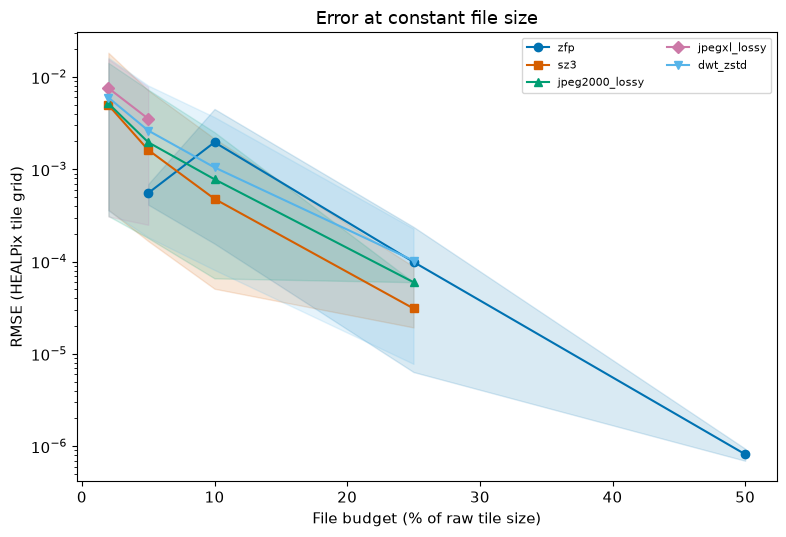

,budget_fraction,codec,median_rmse,lo_rmse,hi_rmse,n_scenes
0,0.50,zfp,8.192466e-07,6.965572e-07,9.419359e-07,2
1,0.25,zfp,9.917312e-05,6.364875e-06,2.378623e-04,7
2,0.25,sz3,3.107973e-05,1.936408e-05,8.849592e-05,5
3,0.25,jpeg2000_lossy,5.983928e-05,5.983928e-05,5.983928e-05,1
4,0.25,dwt_zstd,1.026003e-04,7.799402e-06,2.280991e-04,5
5,0.10,zfp,1.962252e-03,1.566261e-04,4.497590e-03,6
6,0.10,sz3,4.782104e-04,5.083313e-05,2.146510e-03,7
7,0.10,jpeg2000_lossy,7.792794e-04,6.579950e-05,2.521315e-03,7
8,0.10,dwt_zstd,1.047731e-03,8.117008e-05,3.677554e-03,7
9,0.05,zfp,5.524034e-04,4.136467e-04,6.911601e-04,2


In [8]:
# --- Figure "error at constant size": fixed size budgets (fraction of raw) -
FILE_BUDGET_FRACTIONS = [0.5, 0.25, 0.1, 0.05, 0.02]

matched_size_rows = []
for frac in FILE_BUDGET_FRACTIONS:
    target_bytes = frac * raw_bytes
    for codec in COMPRESSOR_CODECS:
        rmses = [interp_rmse_at_size(FRONTIERS[(s, codec)], target_bytes)
                 for s in TILES if (s, codec) in FRONTIERS]
        rmses = [r for r in rmses if np.isfinite(r)]
        if not rmses:
            continue
        matched_size_rows.append(dict(
            budget_fraction=frac, codec=codec,
            median_rmse=float(np.median(rmses)),
            lo_rmse=float(np.min(rmses)), hi_rmse=float(np.max(rmses)),
            n_scenes=len(rmses),
        ))
matched_size_df = pd.DataFrame(matched_size_rows)
matched_size_df.to_csv(RESULTS_DIR / "hpx_matched_size.csv", index=False)

fig, ax = plt.subplots()
for codec in COMPRESSOR_CODECS:
    sub = matched_size_df[matched_size_df.codec == codec].sort_values("budget_fraction")
    if sub.empty:
        continue
    style = CODEC_STYLE[codec]
    ax.plot(sub["budget_fraction"] * 100, sub["median_rmse"],
             color=style["color"], marker=style["marker"], label=codec)
    ax.fill_between(sub["budget_fraction"] * 100, sub["lo_rmse"], sub["hi_rmse"],
                     color=style["color"], alpha=0.15)
ax.set_xlabel("File budget (% of raw tile size)")
ax.set_ylabel("RMSE (HEALPix tile grid)")
ax.set_yscale("log")
ax.legend(fontsize=8, ncol=2)
ax.set_title("Error at constant file size")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_error_at_constant_size.pdf")
fig.savefig(FIGURES_DIR / "fig_error_at_constant_size.png", dpi=150)
plt.show()
matched_size_df